# Imports

In [110]:
# Get imports and functions needed
%run BaseFiles/Imports.ipynb
%run BaseFiles/Functions.ipynb

# Set global variables
colour1 = "royalblue"
colour2 = "red"
colour3 = "yellow"


# Read data from files

In [111]:
# Places to get and save files
DataDirectory = "Data/windData/"
dataName = "wind_min_b"
PlotDirectory = "Plots/WindYearlyPlots/"

# Details: Yearly, minutely data, bow-shock shifted

In [112]:
# Variables
DataSource = "Wind"

TimeFrames = [["1996-01-01 00:00","1996-02-01 00:00"], ["1996-1-01 00:00", "1996-12-01 00:00"], ["2000-01-01 00:00", "2000-12-01 00:00"] ] # Basic, Maximum, Minimum
# Basic
# # Start  = "1996-01-01 00:00"
# # End = "1996-02-01 00:00"
# Minimum
# # Start  = "1996-06-01 00:00"
# # End = "1996-07-01 00:00"
# Maximum
# # Start  = "2000-06-01 00:00"
# # End = "2000-07-01 00:00"



# Read data to dataframes

In [113]:
print(len(TimeFrames))

3


In [121]:
dataTimeSerieses = [[],[],[]] # empty array for data

for j in range(len(TimeFrames)):
    Start = TimeFrames[j][0]
    End = TimeFrames[j][1]
    #Separated by data source as files may have different file name conventions
    if DataSource == "Wind": # If WIND data
        YearlyRange = Yearly(Start, End, frequency = 'MS') #Get range of dates needed # changed to monthly
        print(YearlyRange)
        # dataTimeSerieses = [] # empty array for data
        # StartAndEnd = [] # empty array for start and end times
        for i in range(len(YearlyRange)-1): # for each date range in time range needed
            StartDate = YearlyRange[i] # first file in range
            if YearlyRange[i][4:6] == "01" or YearlyRange[i][4:6] == "03" or YearlyRange[i][4:6] == "05" or YearlyRange[i][4:6] == "07" or YearlyRange[i][4:6] == "08" or YearlyRange[i][4:6] == "10" or YearlyRange[i][4:6] == "12":
                EndDate = YearlyRange[i][0:6] + "31" # last file in range
            elif YearlyRange[i][4:6] == "02":
                if YearlyRange[i][0:4] == "2000" or YearlyRange[i][0:4] == "2008" or YearlyRange[i][0:4] == "2016" or YearlyRange[i][0:4] == "2024":
                    EndDate = YearlyRange[i][0:6] + "29" # last file in range
                else:
                    EndDate = YearlyRange[i][0:6] + "28" # last file in range
            elif YearlyRange[i][4:6] == "04" or YearlyRange[i][4:6] == "06" or YearlyRange[i][4:6] == "09" or YearlyRange[i][4:6] == "11":
                EndDate = YearlyRange[i][0:6] + "30" # last file in range            
            # print(StartDate, EndDate)
            # DateRange = ReadDates(StartDate, EndDate) # get date range
            dataFound = FindDataWind(DataDirectory, dataName, StartDate, EndDate) # find data
            dataTS = dfToSeries(dataFound) # convert to timeseries
            dataTS = AddTotVsw(dataTS) # add totvsw
            dataTS = AddBMag(dataTS) # add bmag
            # dataTS = AddLogBMag(dataTS) 
            # dataTS = AddLogBX(dataTS)
            dataTimeSerieses[j].append(dataTS) # add to data array
            # StartAndEnd.append([StartDate, EndDate]) # add start and end dates to times array

    else: # if not wind (or other coded sources)
        print("Data source not known") # give error message


['19960101', '19960201']
['19960101', '19960201', '19960301', '19960401', '19960501', '19960601', '19960701', '19960801', '19960901', '19961001', '19961101', '19961201']
['20000101', '20000201', '20000301', '20000401', '20000501', '20000601', '20000701', '20000801', '20000901', '20001001', '20001101', '20001201']


In [130]:
# print(dataTimeSerieses)
# print(len(dataTimeSerieses))
# print(dataTimeSerieses[0])


In [125]:
def resampleMean(data, rate, label = "right"):
    resampled = data.to_dataframe().resample(rate, label=label).mean()
    resampledTS = TimeSeries(resampled)
    return resampledTS

File not saved
File not saved
File not saved
Variance of raw data = 5618.674816153802
Variance of resampled (1h) data = 5534.4558497060625
Variance of resampled (2h) data = 5474.9214019563315
DateTime
1996-01-01 00:00:00    1.0
1996-01-01 00:01:00    1.0
1996-01-01 00:02:00    1.0
1996-01-01 00:03:00    1.0
1996-01-01 00:04:00    1.0
                      ... 
1996-01-31 23:55:00    1.0
1996-01-31 23:56:00    1.0
1996-01-31 23:57:00    1.0
1996-01-31 23:58:00    1.0
1996-01-31 23:59:00    1.0
Name: TotVsw, Length: 44640, dtype: float64
DateTime
1996-01-01 01:00:00    1.0
1996-01-01 02:00:00    1.0
1996-01-01 03:00:00    1.0
1996-01-01 04:00:00    1.0
1996-01-01 05:00:00    1.0
                      ... 
1996-01-31 20:00:00    1.0
1996-01-31 21:00:00    1.0
1996-01-31 22:00:00    1.0
1996-01-31 23:00:00    1.0
1996-02-01 00:00:00    1.0
Freq: h, Name: TotVsw, Length: 744, dtype: float64


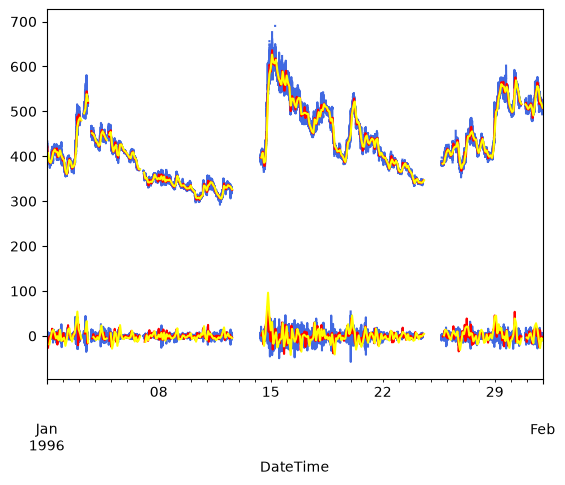

File not saved
File not saved
File not saved
Variance of raw data = 5618.674816153802
Variance of resampled (1h) data = 5534.4558497060625
Variance of resampled (2h) data = 5474.9214019563315
DateTime
1996-01-01 00:00:00    1.0
1996-01-01 00:01:00    1.0
1996-01-01 00:02:00    1.0
1996-01-01 00:03:00    1.0
1996-01-01 00:04:00    1.0
                      ... 
1996-01-31 23:55:00    1.0
1996-01-31 23:56:00    1.0
1996-01-31 23:57:00    1.0
1996-01-31 23:58:00    1.0
1996-01-31 23:59:00    1.0
Name: TotVsw, Length: 44640, dtype: float64
DateTime
1996-01-01 01:00:00    1.0
1996-01-01 02:00:00    1.0
1996-01-01 03:00:00    1.0
1996-01-01 04:00:00    1.0
1996-01-01 05:00:00    1.0
                      ... 
1996-01-31 20:00:00    1.0
1996-01-31 21:00:00    1.0
1996-01-31 22:00:00    1.0
1996-01-31 23:00:00    1.0
1996-02-01 00:00:00    1.0
Freq: h, Name: TotVsw, Length: 744, dtype: float64
File not saved
File not saved
File not saved
Variance of raw data = 4140.880779325437
Variance of res

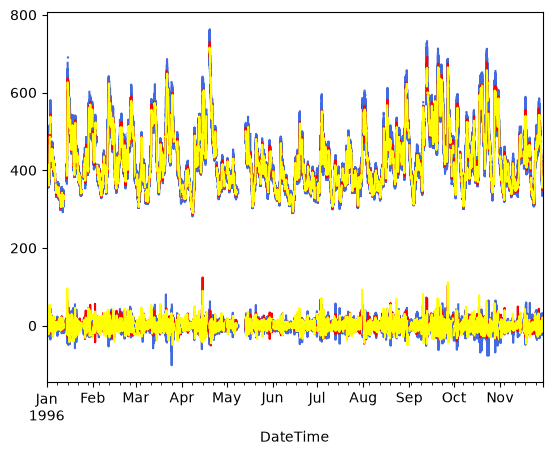

File not saved
File not saved
File not saved
Variance of raw data = 28880.074588565483
Variance of resampled (1h) data = 28492.68587358919
Variance of resampled (2h) data = 28798.935092996377
DateTime
2000-01-01 00:00:00    1.0
2000-01-01 00:01:00    1.0
2000-01-01 00:02:00    1.0
2000-01-01 00:03:00    1.0
2000-01-01 00:04:00    1.0
                      ... 
2000-01-31 23:55:00    1.0
2000-01-31 23:56:00    1.0
2000-01-31 23:57:00    1.0
2000-01-31 23:58:00    1.0
2000-01-31 23:59:00    1.0
Name: TotVsw, Length: 44640, dtype: float64
DateTime
2000-01-01 01:00:00    1.0
2000-01-01 02:00:00    1.0
2000-01-01 03:00:00    1.0
2000-01-01 04:00:00    1.0
2000-01-01 05:00:00    1.0
                      ... 
2000-01-31 20:00:00    1.0
2000-01-31 21:00:00    1.0
2000-01-31 22:00:00    1.0
2000-01-31 23:00:00    1.0
2000-02-01 00:00:00    1.0
Freq: h, Name: TotVsw, Length: 744, dtype: float64
File not saved
File not saved
File not saved
Variance of raw data = 13202.936585788228
Variance of re

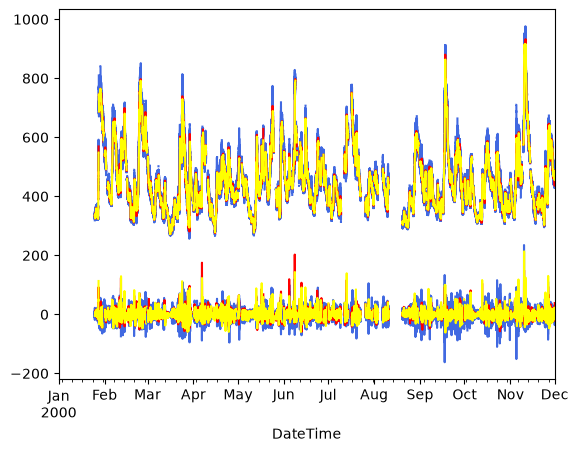

In [ ]:
#Variables
rate1 = "1h"
rate2 = "2h"

# Columns = ["TotVsw"]#, "Vx_GSE", "Vy_GSE", "Vz_GSE"]
# # # xlim = [Start, End]
# ZoomStart = "1996-01-01 00:00"
# ZoomEnd = "1996-01-01 04:00"
# xlim = [ZoomStart, ZoomEnd]
# # ylim = [250, 700]
# ylim = [-65, 700]

fig, ax = plt.subplots()

dataCut = [[0,1], [2,13], [14,]]

for i in range(len(dataTimeSerieses)):
    for j in range(len(dataTimeSerieses[i])):
        rawData = dataTimeSerieses[i][j]
        # rawDataDF = dataTimeSerieses[i][j].to_dataframe()
        # Resample data - Choose a resample rate that seems accurate to changes in data
        resampledRate1 = resampleMean(rawData, rate1)
        resampledRate2 = resampleMean(rawData, rate2)

        # Plo
        PlotVsw(rawData, Columns=["TotVsw"], Label = "Raw data", Color=colour1)
        PlotVsw(resampledRate1, Columns=["TotVsw"], Label = "Resampled: " + rate1, Color=colour2)
        PlotVsw(resampledRate2, Columns=["TotVsw"], Label = "Resampled: " + rate1, Color=colour3)
        # plt.show()
        # plt.xlim([ZoomStart, ZoomEnd])
        


        # Calculate variance of data
        VarRD = rawData.to_dataframe()["TotVsw"].var()
        print( "Variance of raw data = " + str(VarRD))
        VarRate1 = resampledRate1.to_dataframe()["TotVsw"].var()
        print( "Variance of resampled (" + rate1 + ") data = " + str(VarRate1))
        VarRate2 = resampledRate2.to_dataframe()["TotVsw"].var()
        print( "Variance of resampled (" + rate2 + ") data = " + str(VarRate2))

        # Plot "derivative" of data
        DiffRD = rawData.to_dataframe()["TotVsw"].diff()
        DiffRate1 = resampledRate1.to_dataframe()["TotVsw"].diff()
        DiffRate2 = resampledRate2.to_dataframe()["TotVsw"].diff()
        # print(Diff)
        # print(DiffResampled)

        DiffRD.plot(color=colour1)
        DiffRate1.plot(color=colour2)
        DiffRate2.plot(color=colour3)

        ThresholdOfChange = 50
        # DiffSteadyOrNot = Diff.where(abs(Diff) < ThresholdOfChange, "notsteady") # .where() replaces where the condition is NOT met (False)
        # DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) > ThresholdOfChange, "steady")
        # # DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) != np.nan, "nan") # get nans back
        DiffRDSteadyOrNot = DiffRD.where(abs(DiffRD) < ThresholdOfChange, 0) # .where() replaces where the condition is NOT met (False)
        DiffRDSteadyOrNot = DiffRDSteadyOrNot.where(abs(DiffRD) > ThresholdOfChange, 1)
        print(DiffRDSteadyOrNot)

        # DiffResampledSteadyOrNot = DiffResampled.where(abs(DiffResampled) < ThresholdOfChange, "notsteady") # .where() replaces where the condition is NOT met (False)
        # DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) > ThresholdOfChange, "steady")
        # # DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) != np.nan, "nan") # get nans back
        DiffRate1SteadyOrNot = DiffRate1.where(abs(DiffRate1) < ThresholdOfChange, 0) # .where() replaces where the condition is NOT met (False)
        DiffRate1SteadyOrNot = DiffRate1SteadyOrNot.where(abs(DiffRate1) > ThresholdOfChange, 1)
        print(DiffRate1SteadyOrNot)

        # DiffResampledSteadyOrNotAdj = DiffResampledSteadyOrNot*100
        # DiffResampledSteadyOrNotAdj.plot(color="yellow")


    # print( "unique values = " + str(DiffResampledSteadyOrNotAdj.value_counts()))
    plt.show()


NameError: name 'resampledTS' is not defined

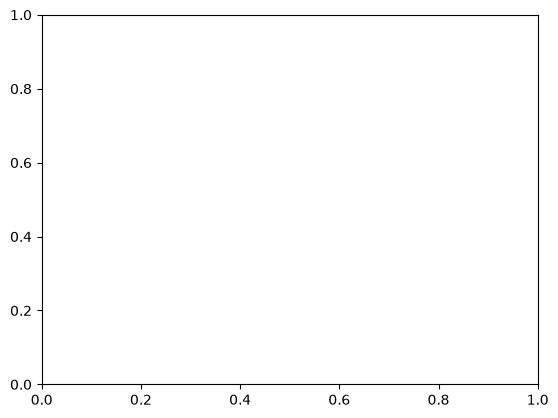

In [89]:



fig, ax = plt.subplots()
# Plot timeseries with raw data

# Plot timeseries with resampled data
PlotVsw(resampledTS, Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = colour2, Label = "Resampled at " + rate)
# PlotVsw(resampledTS2, Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = colour3, Label = "Resampled at " + rate2)

# PlotVsw(dataTimeSerieses[0].resample("5min").sum(), Columns=["TotVsw"], XLim = xlim) # .sum() or no?

# Calculate variance of data
dataTimeSeriesVar = dataTimeSerieses[0].to_dataframe()["TotVsw"].var()
print( "Variance of raw data = " + str(dataTimeSeriesVar))
dataTimeSeriesVar = resampled["TotVsw"].var()
print( "Variance of resampled (" + rate + ") data = " + str(dataTimeSeriesVar))
dataTimeSeriesVar = resampled2["TotVsw"].var()
print( "Variance of resampled (" + rate2 + ") data = " + str(dataTimeSeriesVar))

# Plot "derivative" of data

Diff = dataTimeSerieses[0].to_dataframe()["TotVsw"].diff()
DiffResampled = resampled["TotVsw"].diff()
print(Diff)
print(DiffResampled)


Diff.plot(color=colour1)
DiffResampled.plot(color=colour2)

ThresholdOfChange = 50
# DiffSteadyOrNot = Diff.where(abs(Diff) < ThresholdOfChange, "notsteady") # .where() replaces where the condition is NOT met (False)
# DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) > ThresholdOfChange, "steady")
# # DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) != np.nan, "nan") # get nans back
DiffSteadyOrNot = Diff.where(abs(Diff) < ThresholdOfChange, 0) # .where() replaces where the condition is NOT met (False)
DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) > ThresholdOfChange, 1)
print(DiffSteadyOrNot)

# DiffResampledSteadyOrNot = DiffResampled.where(abs(DiffResampled) < ThresholdOfChange, "notsteady") # .where() replaces where the condition is NOT met (False)
# DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) > ThresholdOfChange, "steady")
# # DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) != np.nan, "nan") # get nans back
DiffResampledSteadyOrNot = DiffResampled.where(abs(DiffResampled) < ThresholdOfChange, 0) # .where() replaces where the condition is NOT met (False)
DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) > ThresholdOfChange, 1)
print(DiffResampledSteadyOrNot)

DiffResampledSteadyOrNotAdj = DiffResampledSteadyOrNot*100
DiffResampledSteadyOrNotAdj.plot(color="yellow")


print( "unique values = " + str(DiffResampledSteadyOrNotAdj.value_counts()))
# DiffAdj = []
# for i in range(len(Diff)):
#     diffAdj = Diff.values[i] + (dataTimeSerieses[0].to_dataframe()["TotVsw"].mean())
#     DiffAdj.append(diffAdj)

# DiffAdj.plot()



# derivative = []
# # dataToDerive = dataTimeSerieses[0].to_dataframe()["TotVsw"]
# dataToDerive = resampled["TotVsw"]
# # dataToDerive = resampled2["TotVsw"]

# for i in range(len(dataToDerive)-1):
#     y_diff = dataToDerive.values[i+1]-dataToDerive.values[i]
#     derivative.append(y_diff)


# # derivative10 = []
# d = {"TotVswDev": derivative}
# derivative = pd.DataFrame(data=d, index=dataToDerive.index[0:-1])
# print(derivative)
# ax.plot(derivative, markersize=10)
# # derivative.plot()
# # for j in range(len(derivative)):
# #     derivative10.append(derivative[j]*10)

# # derivative.plot() # , alpha = 0.5)
# # PlotVsw(derivative["TotVswDev"],  XLim = xlim, YLim = ylim, Color = colour1, Label = "Raw data")
# # plt.plot(dataToDerive.index[0:-1], derivative, color="green")


# print("Caption: Raw data ("+str(color1) + ") and data resampled at " + rate + " resample rate ("+str(color2) + ") and "+ rate2 + " resample rate ("+str(color3) + ").")





# At maximum

In [50]:

#Separated by data source as files may have different file name conventions
if DataSource == "Wind": # If WIND data
    YearlyRange = Yearly(Start, End, frequency = 'MS') #Get range of dates needed # changed to monthly
    print(YearlyRange)
    dataTimeSerieses = [] # empty array for data
    # StartAndEnd = [] # empty array for start and end times
    for i in range(len(YearlyRange)-1): # for each date range in time range needed
        StartDate = YearlyRange[i] # first file in range
        if YearlyRange[i][4:6] == "01" or YearlyRange[i][4:6] == "03" or YearlyRange[i][4:6] == "05" or YearlyRange[i][4:6] == "07":
            EndDate = YearlyRange[i][0:6] + "31" # last file in range
        elif YearlyRange[i][4:6] == "02":
            EndDate = YearlyRange[i][0:6] + "29" # last file in range
        elif YearlyRange[i][4:6] == "04" or YearlyRange[i][4:6] == "06" or YearlyRange[i][4:6] == "08":
                EndDate = YearlyRange[i][0:6] + "30" # last file in range
        # print(StartDate, EndDate)
        # DateRange = ReadDates(StartDate, EndDate) # get date range
        dataFound = FindDataWind(DataDirectory, dataName, StartDate, EndDate) # find data
        dataTS = dfToSeries(dataFound) # convert to timeseries
        dataTS = AddTotVsw(dataTS) # add totvsw
        # dataTS = AddBMag(dataTS) # add bmag
        # dataTS = AddLogBMag(dataTS) 
        # dataTS = AddLogBX(dataTS)
        dataTimeSerieses.append(dataTS) # add to data array
        # StartAndEnd.append([StartDate, EndDate]) # add start and end dates to times array

else: # if not wind (or other coded sources)
    print("Data source not known") # give error message


['20000601', '20000701']


In [51]:
# Resample data - Choose a resample rate that seems accurate to changes in data

rate = "1h"
# print(dataTimeSerieses[0])
resampled = dataTimeSerieses[0].to_dataframe().resample(rate, label="right").mean() 
# print(resampled)
resampledTS = TimeSeries(resampled)
# print(resampledTS)

rate2 = "2h"
# print(dataTimeSerieses[0])
resampled2 = dataTimeSerieses[0].to_dataframe().resample(rate2, label="right").mean() 
# print(resampled2)
resampledTS2 = TimeSeries(resampled2)
# print(resampledTS2)


File not saved
File not saved
Variance of raw data = 5637.240434991073
Variance of resampled (1h) data = 5442.308308061471
Variance of resampled (2h) data = 5581.324188640271
DateTime
2000-06-01 00:00:00          NaN
2000-06-01 00:01:00     6.282770
2000-06-01 00:02:00   -14.603672
2000-06-01 00:03:00    11.316637
2000-06-01 00:04:00    -5.682817
                         ...    
2000-06-30 23:55:00          NaN
2000-06-30 23:56:00          NaN
2000-06-30 23:57:00          NaN
2000-06-30 23:58:00     0.000000
2000-06-30 23:59:00     0.000000
Name: TotVsw, Length: 43200, dtype: float64
DateTime
2000-06-01 01:00:00          NaN
2000-06-01 02:00:00    -0.150429
2000-06-01 03:00:00    26.230158
2000-06-01 04:00:00   -13.617836
2000-06-01 05:00:00    -3.605912
                         ...    
2000-06-30 20:00:00     7.835255
2000-06-30 21:00:00    -8.110345
2000-06-30 22:00:00   -11.743474
2000-06-30 23:00:00     7.250561
2000-07-01 00:00:00    14.725155
Freq: h, Name: TotVsw, Length: 720, d

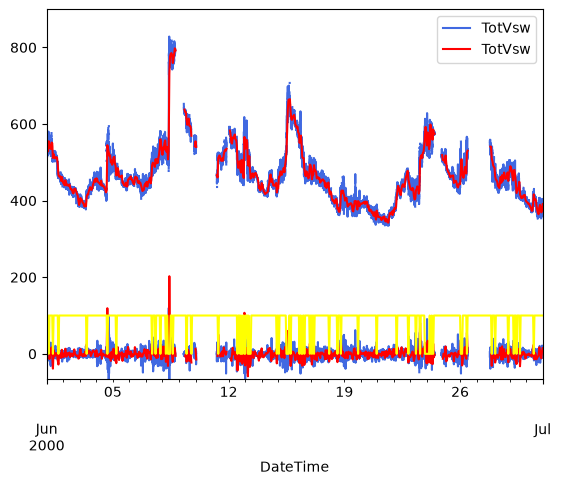

In [ ]:
Columns = ["TotVsw"]#, "Vx_GSE", "Vy_GSE", "Vz_GSE"]
# xlim = [Start, End]
ZoomStart = "2000-01-01 00:00"
ZoomEnd = "2000-01-01 04:00"
xlim = [ZoomStart, ZoomEnd]
# ylim = [250, 700]
ylim = [-65, 900]
colour3 = "yellow"

fig, ax = plt.subplots()
# Plot timeseries with raw data
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = colour1, Label = "Raw data")

# Plot timeseries with resampled data
PlotVsw(resampledTS, Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = colour2, Label = "Resampled at " + rate)
# PlotVsw(resampledTS2, Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = colour3, Label = "Resampled at " + rate2)

# PlotVsw(dataTimeSerieses[0].resample("5min").sum(), Columns=["TotVsw"], XLim = xlim) # .sum() or no?

# Calculate variance of data
dataTimeSeriesVar = dataTimeSerieses[0].to_dataframe()["TotVsw"].var()
print( "Variance of raw data = " + str(dataTimeSeriesVar))
dataTimeSeriesVar = resampled["TotVsw"].var()
print( "Variance of resampled (" + rate + ") data = " + str(dataTimeSeriesVar))
dataTimeSeriesVar = resampled2["TotVsw"].var()
print( "Variance of resampled (" + rate2 + ") data = " + str(dataTimeSeriesVar))

# Plot "derivative" of data

Diff = dataTimeSerieses[0].to_dataframe()["TotVsw"].diff()
DiffResampled = resampled["TotVsw"].diff()
print(Diff)
print(DiffResampled)


Diff.plot(color=colour1)
DiffResampled.plot(color=colour2)

ThresholdOfChange = 20
# DiffSteadyOrNot = Diff.where(abs(Diff) < ThresholdOfChange, "notsteady") # .where() replaces where the condition is NOT met (False)
# DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) > ThresholdOfChange, "steady")
# # DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) != np.nan, "nan") # get nans back
DiffSteadyOrNot = Diff.where(abs(Diff) < ThresholdOfChange, 0) # .where() replaces where the condition is NOT met (False)
DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) > ThresholdOfChange, 1)
print(DiffSteadyOrNot)

# DiffResampledSteadyOrNot = DiffResampled.where(abs(DiffResampled) < ThresholdOfChange, "notsteady") # .where() replaces where the condition is NOT met (False)
# DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) > ThresholdOfChange, "steady")
# # DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) != np.nan, "nan") # get nans back
DiffResampledSteadyOrNot = DiffResampled.where(abs(DiffResampled) < ThresholdOfChange, 0) # .where() replaces where the condition is NOT met (False)
DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) > ThresholdOfChange, 1)
print(DiffResampledSteadyOrNot)

DiffResampledSteadyOrNotAdj = DiffResampledSteadyOrNot*100
DiffResampledSteadyOrNotAdj.plot(color="yellow")


print( "unique values = " + str(DiffResampledSteadyOrNotAdj.value_counts()))
# DiffAdj = []
# for i in range(len(Diff)):
#     diffAdj = Diff.values[i] + (dataTimeSerieses[0].to_dataframe()["TotVsw"].mean())
#     DiffAdj.append(diffAdj)

# DiffAdj.plot()



# derivative = []
# # dataToDerive = dataTimeSerieses[0].to_dataframe()["TotVsw"]
# dataToDerive = resampled["TotVsw"]
# # dataToDerive = resampled2["TotVsw"]

# for i in range(len(dataToDerive)-1):
#     y_diff = dataToDerive.values[i+1]-dataToDerive.values[i]
#     derivative.append(y_diff)


# # derivative10 = []
# d = {"TotVswDev": derivative}
# derivative = pd.DataFrame(data=d, index=dataToDerive.index[0:-1])
# print(derivative)
# ax.plot(derivative, markersize=10)
# # derivative.plot()
# # for j in range(len(derivative)):
# #     derivative10.append(derivative[j]*10)

# # derivative.plot() # , alpha = 0.5)
# # PlotVsw(derivative["TotVswDev"],  XLim = xlim, YLim = ylim, Color = color1, Label = "Raw data")
# # plt.plot(dataToDerive.index[0:-1], derivative, color="green")


# print("Caption: Raw data ("+str(color1) + ") and data resampled at " + rate + " resample rate ("+str(color2) + ") and "+ rate2 + " resample rate ("+str(color3) + ").")





# At minimum

In [55]:

#Separated by data source as files may have different file name conventions
if DataSource == "Wind": # If WIND data
    YearlyRange = Yearly(Start, End, frequency = 'MS') #Get range of dates needed # changed to monthly
    print(YearlyRange)
    dataTimeSerieses = [] # empty array for data
    # StartAndEnd = [] # empty array for start and end times
    for i in range(len(YearlyRange)-1): # for each date range in time range needed
        StartDate = YearlyRange[i] # first file in range
        if YearlyRange[i][4:6] == "01" or YearlyRange[i][4:6] == "03" or YearlyRange[i][4:6] == "05" or YearlyRange[i][4:6] == "07":
            EndDate = YearlyRange[i][0:6] + "31" # last file in range
        elif YearlyRange[i][4:6] == "02":
            EndDate = YearlyRange[i][0:6] + "29" # last file in range
        elif YearlyRange[i][4:6] == "04" or YearlyRange[i][4:6] == "06" or YearlyRange[i][4:6] == "08":
                EndDate = YearlyRange[i][0:6] + "30" # last file in range
        # print(StartDate, EndDate)
        # DateRange = ReadDates(StartDate, EndDate) # get date range
        dataFound = FindDataWind(DataDirectory, dataName, StartDate, EndDate) # find data
        dataTS = dfToSeries(dataFound) # convert to timeseries
        dataTS = AddTotVsw(dataTS) # add totvsw
        # dataTS = AddBMag(dataTS) # add bmag
        # dataTS = AddLogBMag(dataTS) 
        # dataTS = AddLogBX(dataTS)
        dataTimeSerieses.append(dataTS) # add to data array
        # StartAndEnd.append([StartDate, EndDate]) # add start and end dates to times array

else: # if not wind (or other coded sources)
    print("Data source not known") # give error message


['19960601', '19960701']


In [56]:
# Resample data - Choose a resample rate that seems accurate to changes in data

rate = "1h"
# print(dataTimeSerieses[0])
resampled = dataTimeSerieses[0].to_dataframe().resample(rate, label="right").mean() 
# print(resampled)
resampledTS = TimeSeries(resampled)
# print(resampledTS)

rate2 = "2h"
# print(dataTimeSerieses[0])
resampled2 = dataTimeSerieses[0].to_dataframe().resample(rate2, label="right").mean() 
# print(resampled2)
resampledTS2 = TimeSeries(resampled2)
# print(resampledTS2)


File not saved
File not saved
Variance of raw data = 1680.0279445182925
Variance of resampled (1h) data = 1669.6038084496151
Variance of resampled (2h) data = 1657.0670481870395
DateTime
1996-06-01 00:00:00    NaN
1996-06-01 00:01:00    NaN
1996-06-01 00:02:00    NaN
1996-06-01 00:03:00    0.0
1996-06-01 00:04:00    0.0
                      ... 
1996-06-30 23:55:00    NaN
1996-06-30 23:56:00    NaN
1996-06-30 23:57:00    NaN
1996-06-30 23:58:00    NaN
1996-06-30 23:59:00    0.0
Name: TotVsw, Length: 43200, dtype: float64
DateTime
1996-06-01 01:00:00          NaN
1996-06-01 02:00:00     7.968825
1996-06-01 03:00:00          NaN
1996-06-01 04:00:00          NaN
1996-06-01 05:00:00          NaN
                         ...    
1996-06-30 20:00:00     4.151094
1996-06-30 21:00:00    18.054562
1996-06-30 22:00:00    20.816307
1996-06-30 23:00:00   -16.729335
1996-07-01 00:00:00    -1.195418
Freq: h, Name: TotVsw, Length: 720, dtype: float64
DateTime
1996-06-01 00:00:00    1.0
1996-06-01 00

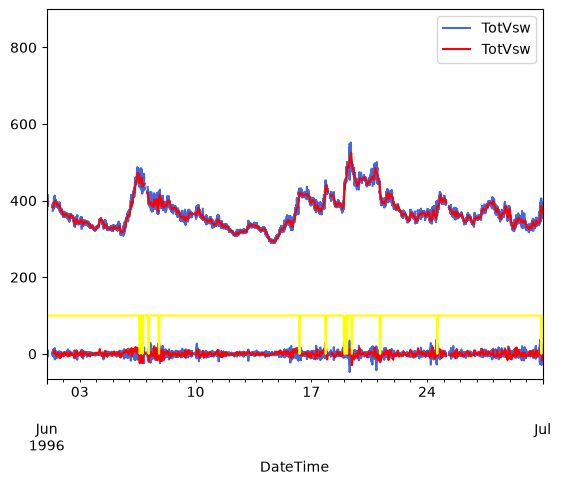

In [ ]:
Columns = ["TotVsw"]#, "Vx_GSE", "Vy_GSE", "Vz_GSE"]
# xlim = [Start, End]
ZoomStart = "2000-01-01 00:00"
ZoomEnd = "2000-01-01 04:00"
xlim = [ZoomStart, ZoomEnd]
# ylim = [250, 700]
ylim = [-65, 900]
color1 = "royalblue"
color2 = "red"
color3 = "yellow"

fig, ax = plt.subplots()
# Plot timeseries with raw data
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color1, Label = "Raw data")

# Plot timeseries with resampled data
PlotVsw(resampledTS, Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color2, Label = "Resampled at " + rate)
# PlotVsw(resampledTS2, Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color3, Label = "Resampled at " + rate2)

# PlotVsw(dataTimeSerieses[0].resample("5min").sum(), Columns=["TotVsw"], XLim = xlim) # .sum() or no?

# Calculate variance of data
dataTimeSeriesVar = dataTimeSerieses[0].to_dataframe()["TotVsw"].var()
print( "Variance of raw data = " + str(dataTimeSeriesVar))
dataTimeSeriesVar = resampled["TotVsw"].var()
print( "Variance of resampled (" + rate + ") data = " + str(dataTimeSeriesVar))
dataTimeSeriesVar = resampled2["TotVsw"].var()
print( "Variance of resampled (" + rate2 + ") data = " + str(dataTimeSeriesVar))

# Plot "derivative" of data

Diff = dataTimeSerieses[0].to_dataframe()["TotVsw"].diff()
DiffResampled = resampled["TotVsw"].diff()
print(Diff)
print(DiffResampled)


Diff.plot(color=color1)
DiffResampled.plot(color=color2)

ThresholdOfChange = 20
# DiffSteadyOrNot = Diff.where(abs(Diff) < ThresholdOfChange, "notsteady") # .where() replaces where the condition is NOT met (False)
# DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) > ThresholdOfChange, "steady")
# # DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) != np.nan, "nan") # get nans back
DiffSteadyOrNot = Diff.where(abs(Diff) < ThresholdOfChange, 0) # .where() replaces where the condition is NOT met (False)
DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) > ThresholdOfChange, 1)
print(DiffSteadyOrNot)

# DiffResampledSteadyOrNot = DiffResampled.where(abs(DiffResampled) < ThresholdOfChange, "notsteady") # .where() replaces where the condition is NOT met (False)
# DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) > ThresholdOfChange, "steady")
# # DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) != np.nan, "nan") # get nans back
DiffResampledSteadyOrNot = DiffResampled.where(abs(DiffResampled) < ThresholdOfChange, 0) # .where() replaces where the condition is NOT met (False)
DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) > ThresholdOfChange, 1)
print(DiffResampledSteadyOrNot)

DiffResampledSteadyOrNotAdj = DiffResampledSteadyOrNot*100
DiffResampledSteadyOrNotAdj.plot(color="yellow")


print( "unique values = " + str(DiffResampledSteadyOrNotAdj.value_counts()))
# DiffAdj = []
# for i in range(len(Diff)):
#     diffAdj = Diff.values[i] + (dataTimeSerieses[0].to_dataframe()["TotVsw"].mean())
#     DiffAdj.append(diffAdj)

# DiffAdj.plot()



# derivative = []
# # dataToDerive = dataTimeSerieses[0].to_dataframe()["TotVsw"]
# dataToDerive = resampled["TotVsw"]
# # dataToDerive = resampled2["TotVsw"]

# for i in range(len(dataToDerive)-1):
#     y_diff = dataToDerive.values[i+1]-dataToDerive.values[i]
#     derivative.append(y_diff)


# # derivative10 = []
# d = {"TotVswDev": derivative}
# derivative = pd.DataFrame(data=d, index=dataToDerive.index[0:-1])
# print(derivative)
# ax.plot(derivative, markersize=10)
# # derivative.plot()
# # for j in range(len(derivative)):
# #     derivative10.append(derivative[j]*10)

# # derivative.plot() # , alpha = 0.5)
# # PlotVsw(derivative["TotVswDev"],  XLim = xlim, YLim = ylim, Color = color1, Label = "Raw data")
# # plt.plot(dataToDerive.index[0:-1], derivative, color="green")


# print("Caption: Raw data ("+str(color1) + ") and data resampled at " + rate + " resample rate ("+str(color2) + ") and "+ rate2 + " resample rate ("+str(color3) + ").")





In [58]:
# length = len(Diff)
# Offset = -60
# print(Diff[round(length/2)+ Offset:round(length/2) + Offset+ 20])
# print(DiffSteadyOrNot[round(length/2)+ Offset:round(length/2) + Offset+ 20])

length = len(DiffResampled)
Offset = -60
print(DiffResampled[round(length/2)+ Offset:round(length/2) + Offset+ 20])
print(DiffResampledSteadyOrNot[round(length/2)+ Offset:round(length/2) + Offset+ 20])

DateTime
1996-06-13 13:00:00   -0.017980
1996-06-13 14:00:00   -1.750555
1996-06-13 15:00:00   -0.559265
1996-06-13 16:00:00   -2.635979
1996-06-13 17:00:00    2.457160
1996-06-13 18:00:00   -0.990001
1996-06-13 19:00:00   -3.186328
1996-06-13 20:00:00    1.638167
1996-06-13 21:00:00   -4.515300
1996-06-13 22:00:00   -1.950071
1996-06-13 23:00:00   -2.022839
1996-06-14 00:00:00    1.118670
1996-06-14 01:00:00   -1.085346
1996-06-14 02:00:00    2.727112
1996-06-14 03:00:00    1.433396
1996-06-14 04:00:00   -0.141229
1996-06-14 05:00:00   -3.320692
1996-06-14 06:00:00   -5.207831
1996-06-14 07:00:00   -2.765316
1996-06-14 08:00:00   -4.482521
Freq: h, Name: TotVsw, dtype: float64
DateTime
1996-06-13 13:00:00    1.0
1996-06-13 14:00:00    1.0
1996-06-13 15:00:00    1.0
1996-06-13 16:00:00    1.0
1996-06-13 17:00:00    1.0
1996-06-13 18:00:00    1.0
1996-06-13 19:00:00    1.0
1996-06-13 20:00:00    1.0
1996-06-13 21:00:00    1.0
1996-06-13 22:00:00    1.0
1996-06-13 23:00:00    1.0
1996-06

File not saved
Variance of raw data = 1680.0279445182925
Variance of resampled (1h) data = 1669.6038084496151
Variance of resampled (2h) data = 1657.0670481870395
                     TotVswDev
DateTime                      
1996-06-01 00:00:00        NaN
1996-06-01 00:01:00        NaN
1996-06-01 00:02:00   0.000000
1996-06-01 00:03:00   0.000000
1996-06-01 00:04:00  -2.513142
...                        ...
1996-06-30 23:54:00        NaN
1996-06-30 23:55:00        NaN
1996-06-30 23:56:00        NaN
1996-06-30 23:57:00        NaN
1996-06-30 23:58:00   0.000000

[43199 rows x 1 columns]
Caption: Raw data (royalblue) and data resampled at 1h resample rate (red) and 2h resample rate (yellow).


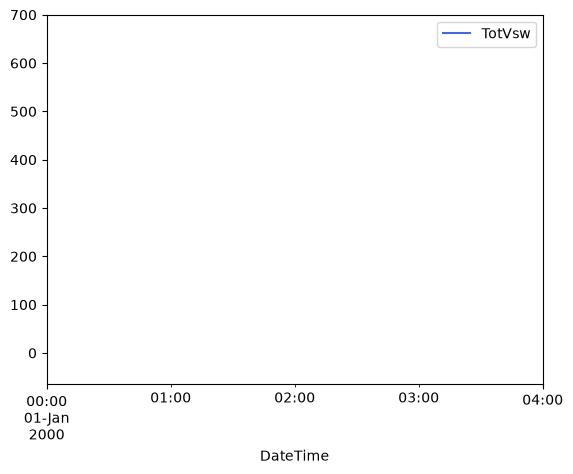

In [ ]:
Columns = ["TotVsw"]#, "Vx_GSE", "Vy_GSE", "Vz_GSE"]
# xlim = [Start, End]
xlim = [ZoomStart, ZoomEnd]
# ylim = [250, 700]
ylim = [-65, 700]
color3 = "yellow"

fig, ax = plt.subplots()
# Plot timeseries with raw data
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color1, Label = "Raw data")

# Plot timeseries with resampled data
# PlotVsw(resampledTS, Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color2, Label = "Resampled at " + rate)
# PlotVsw(resampledTS2, Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color3, Label = "Resampled at " + rate2)

# PlotVsw(dataTimeSerieses[0].resample("5min").sum(), Columns=["TotVsw"], XLim = xlim) # .sum() or no?

# Calculate variance of data
dataTimeSeriesVar = dataTimeSerieses[0].to_dataframe()["TotVsw"].var()
print( "Variance of raw data = " + str(dataTimeSeriesVar))
dataTimeSeriesVar = resampled["TotVsw"].var()
print( "Variance of resampled (" + rate + ") data = " + str(dataTimeSeriesVar))
dataTimeSeriesVar = resampled2["TotVsw"].var()
print( "Variance of resampled (" + rate2 + ") data = " + str(dataTimeSeriesVar))

# Plot "derivative" of data
derivative = []
dataToDerive = dataTimeSerieses[0].to_dataframe()["TotVsw"]
# dataToDerive = resampled["TotVsw"]
# dataToDerive = resampled2["TotVsw"]

for i in range(len(dataToDerive)-1):
    y_diff = dataToDerive.values[i+1]-dataToDerive.values[i]
    derivative.append(y_diff)


# derivative10 = []
d = {"TotVswDev": derivative}
derivative = pd.DataFrame(data=d, index=dataToDerive.index[0:-1])
print(derivative)
ax.plot(derivative, markersize=10)
# derivative.plot()
# for j in range(len(derivative)):
#     derivative10.append(derivative[j]*10)

# derivative.plot() # , alpha = 0.5)
# PlotVsw(derivative["TotVswDev"],  XLim = xlim, YLim = ylim, Color = color1, Label = "Raw data")
# plt.plot(dataToDerive.index[0:-1], derivative, color="green")


print("Caption: Raw data ("+str(color1) + ") and data resampled at " + rate + " resample rate ("+str(color2) + ") and "+ rate2 + " resample rate ("+str(color3) + ").")





File not saved


<Axes: xlabel='DateTime'>

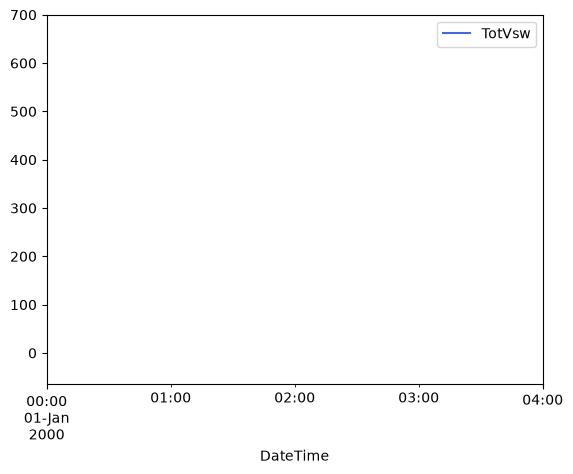

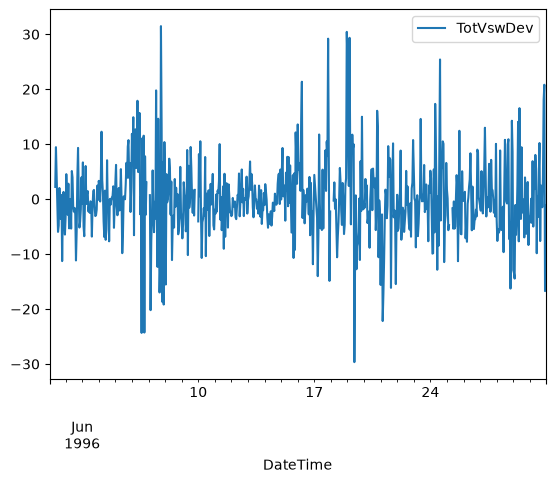

In [ ]:
Columns = ["TotVsw"]#, "Vx_GSE", "Vy_GSE", "Vz_GSE"]
# xlim = [Start, End]
xlim = [ZoomStart, ZoomEnd]
# ylim = [250, 700]
ylim = [-65, 700]
color3 = "yellow"

fig, ax = plt.subplots()
# Plot timeseries with raw data
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color1, Label = "Raw data")

# Plot "derivative" of data
derivative = []
dataToDerive = resampled["TotVsw"]

for i in range(len(dataToDerive)-1):
    y_diff = dataToDerive.values[i+1]-dataToDerive.values[i]
    derivative.append(y_diff)

d = {"TotVswDev": derivative}
derivative = pd.DataFrame(data=d, index=dataToDerive.index[0:-1])

# ax.plot(derivative)
# plt.plot(derivative)
derivative.plot()




In [61]:
# maskFirst = Data.to_dataframe()[Variable].between(Thres-AbsThres, Thres+AbsThres) # get true/false array of data based on condition of values being between the threshold values


[np.float64(nan), np.float64(nan), np.float64(0.0), np.float64(0.0), np.float64(-2.513142008500438), np.float64(0.0), np.float64(0.0), np.float64(nan), np.float64(nan), np.float64(0.053368969022528745), np.float64(1.1020318513919278), np.float64(-1.6956860460394978), np.float64(2.47746238155014), np.float64(-2.115908970647979), np.float64(-0.1071786654147786), np.float64(-2.833594789879953), np.float64(-0.19977259489195376), np.float64(-0.3062248781183712), np.float64(0.8447922645099197), np.float64(-1.5783687078925368), np.float64(3.1682117150608065), np.float64(1.6645819665489512), np.float64(-5.560019533312129), np.float64(0.0), np.float64(3.1099035887606874), np.float64(0.0), np.float64(nan), np.float64(nan), np.float64(-0.6915984807909012), np.float64(-2.353726231574001), np.float64(1.5569818286068084), np.float64(0.4437111895221051), np.float64(-0.38927792908054926), np.float64(-0.00239920744201072), np.float64(0.3818826031873641), np.float64(0.16397385655983499), np.float64(0.12

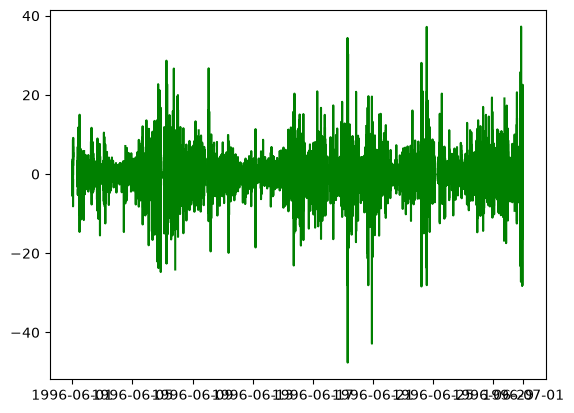

In [ ]:
# Plot "derivative" of data
derivative = []
for i in range(len(dataTimeSerieses[0].to_dataframe())-1):
    y_diff = dataTimeSerieses[0].to_dataframe()["TotVsw"].values[i+1]-dataTimeSerieses[0].to_dataframe()["TotVsw"].values[i]
    derivative.append(y_diff)

print(derivative)
# derivative10 = []

# for j in range(len(derivative)):
#     derivative10.append(derivative[j]*10)

plt.plot(dataTimeSerieses[0].to_dataframe().index[0:-1], derivative, color="green")
# plt.plot(dataTimeSerieses[0].to_dataframe().index[0:-1], derivative10, color="green")

# Plot steady and non-steady regions

# Time series with a lot of steadiness
# Time series with lots of change

# Time series at minimum
# Time series at maximum


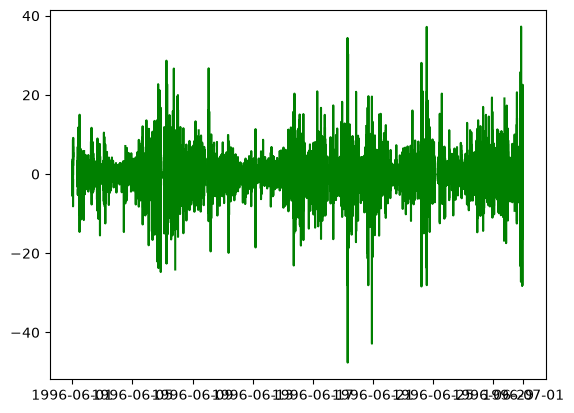

In [ ]:
plt.plot(dataTimeSerieses[0].to_dataframe().index[0:-1], derivative, color="green")
